In [ ]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

ruta = '/content/drive/MyDrive/TpCienciaDatos/'
data = pd.read_csv(ruta + 'Clientes_Demorados_SinDuplicados.csv', sep=';',encoding='latin1')


Mounted at /content/drive


In [ ]:
data = data.drop(columns = "id_cliente")


In [ ]:
data.describe()

,edad,cant_vuelos,gasto_acumulado,gasto_acumulado_extra,cantidad_millas,ingreso_mensual,anticipacion_compra_promedio
count,22391.000000,22391.000000,22391.000000,22391.000000,22391.000000,22391.000000,22391.000000
mean,37.762092,17.064267,6616.264253,953.879531,6853.920906,3072.596490,19.948997
std,11.443856,15.770145,12386.318655,1952.737560,23713.558175,4159.232328,21.371569
min,18.000000,1.000000,73.190000,3.210000,0.000000,300.000000,0.000000
25%,29.000000,7.000000,1412.530000,168.885000,0.000000,1240.000000,5.000000
50%,38.000000,14.000000,3120.780000,405.150000,0.000000,2071.000000,13.000000
75%,46.000000,21.000000,6318.875000,908.830000,0.000000,3797.000000,27.000000
max,80.000000,99.000000,253140.320000,40828.660000,541589.000000,350075.000000,180.000000


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22391 entries, 0 to 22390
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   sexo                          22391 non-null  object 
 1   provincia                     22391 non-null  object 
 2   edad                          22391 non-null  int64  
 3   ocupacion                     22391 non-null  object 
 4   cant_vuelos                   22391 non-null  int64  
 5   clase_preferida               22391 non-null  object 
 6   gasto_acumulado               22391 non-null  float64
 7   gasto_acumulado_extra         22391 non-null  float64
 8   programaMillas                22391 non-null  object 
 9   cantidad_millas               22391 non-null  int64  
 10  ingreso_mensual               22391 non-null  int64  
 11  anticipacion_compra_promedio  22391 non-null  int64  
 12  canal_compra                  22391 non-null  object 
dtypes

In [ ]:
sns.set_style("whitegrid")

In [ ]:
# --- PASO 3: PREPARACIÓN Y ESTANDARIZACIÓN (CORREGIDO) ---

# 1. Eliminación de variables que no aportan al agrupamiento
# Usamos 'data' que es el nombre de tu variable original
cols_a_quitar = ['id_cliente', 'sexo', 'provincia', 'canal_compra']

data_kmeans = data.drop(
    columns=[c for c in cols_a_quitar if c in data.columns],
    errors='ignore'
).copy()

# 2. Codificación binaria de 'programaMillas'
# Cubrimos 'sí' con acento, 'si' sin acento y limpiamos espacios
if 'programaMillas' in data_kmeans.columns:
    data_kmeans['programaMillas'] = (
        data_kmeans['programaMillas']
        .astype(str)
        .str.lower()
        .str.strip()
        .map({'no': 0, 'sí': 1, 'si': 1})
        .fillna(0) # Si hay algo que no es si/no, lo pone como 0
    )

# 3. One-Hot Encoding para variables categóricas
# Esto crea columnas para ocupacion y clase_preferida automáticamente
data_kmeans = pd.get_dummies(
    data_kmeans,
    columns=['ocupacion', 'clase_preferida'],
    drop_first=False
)

# 4. Limpieza de Nulos
# Borramos filas que tengan nulos para que el modelo no falle
print("Nulos antes de limpiar:", data_kmeans.isnull().sum().sum())
data_kmeans = data_kmeans.dropna()

# 5. Estandarización
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
# Transformamos los datos a una misma escala (importante para K-Means)
data_kmeans_scaled = scaler.fit_transform(data_kmeans)

print("¡Hecho! Datos preparados.")
print("Dimensiones finales:", data_kmeans_scaled.shape)

Nulos antes de limpiar: 0
¡Hecho! Datos preparados.
Dimensiones finales: (22391, 26)


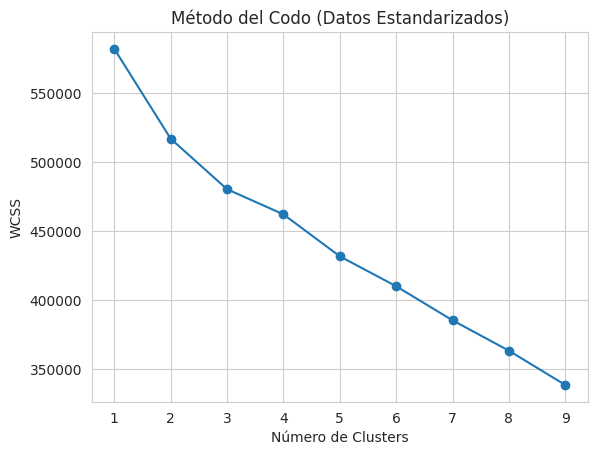

In [ ]:

# --- PASO 4: MÉTODO DEL CODO ---
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []

for i in range(1, 10):
    kmeans = KMeans(
        n_clusters=i,
        n_init=10,
        random_state=0
    )

    # ¡ESTE ES EL CAMBIO! Usamos 'data_kmeans_scaled'
    kmeans.fit(data_kmeans_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 10), wcss, marker='o')
plt.title('Método del Codo (Datos Estandarizados)')
plt.xlabel('Número de Clusters')
plt.ylabel('WCSS')
plt.grid(True) # Le agregamos una grilla para que sea más fácil ver el codo
plt.show()

Para K=2, el coeficiente de silueta es: 0.2843
Para K=3, el coeficiente de silueta es: 0.1656
Para K=4, el coeficiente de silueta es: 0.1087
Para K=5, el coeficiente de silueta es: 0.1687


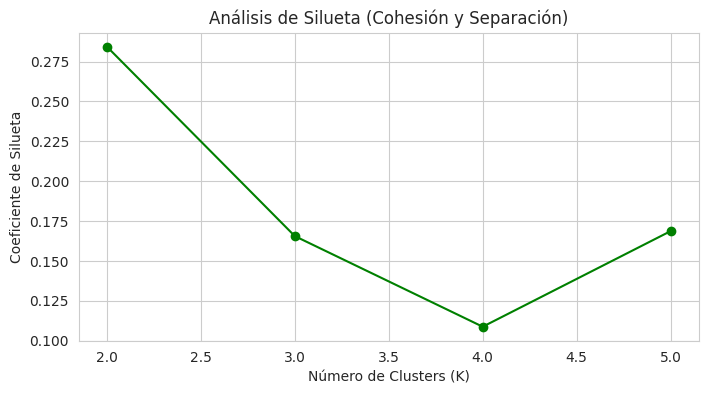

In [ ]:
# --- PASO 4.5: ANÁLISIS DE SILUETA PARA DECIDIR K ---
from sklearn.metrics import silhouette_score

siluetas = []
rango_n_clusters = range(2, 6)

for k in rango_n_clusters:
    # Creamos un modelo temporal para cada K
    kmeans_temp = KMeans(n_clusters=k, n_init=10, random_state=0)
    labels_temp = kmeans_temp.fit_predict(data_kmeans_scaled)

    # Guardamos el score
    score_medio = silhouette_score(data_kmeans_scaled, labels_temp)
    siluetas.append(score_medio)
    print(f"Para K={k}, el coeficiente de silueta es: {score_medio:.4f}")

# Graficar
plt.figure(figsize=(8, 4))
plt.plot(rango_n_clusters, siluetas, marker='o', color='green')
plt.title('Análisis de Silueta (Cohesión y Separación)')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Coeficiente de Silueta')
plt.grid(True)
plt.show()


 EVALUANDO MODELO CON K = 2 


,cantidad_millas,gasto_acumulado,ingreso_mensual,cant_vuelos
Clust,,,,
0,2083.901055,3380.805392,2376.631294,12.379411
1,36011.955210,26393.880159,7326.871665,45.701715


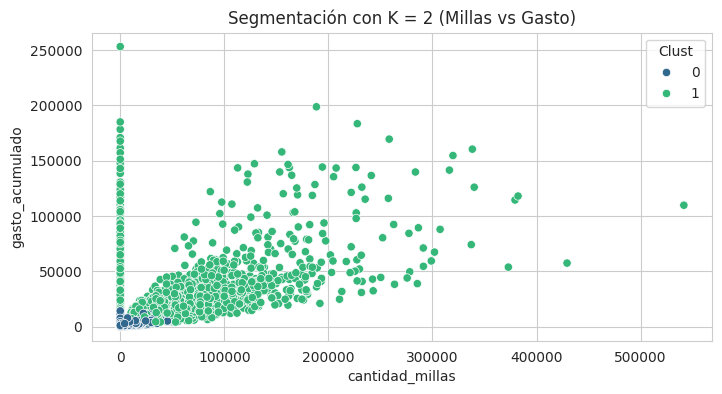


 EVALUANDO MODELO CON K = 3 


,cantidad_millas,gasto_acumulado,ingreso_mensual,cant_vuelos
Clust,,,,
0,1887.210038,2770.262785,2129.900183,12.948105
1,48421.027027,32341.142551,7583.875771,53.789000
2,4842.173412,8140.109824,4301.611350,14.311779


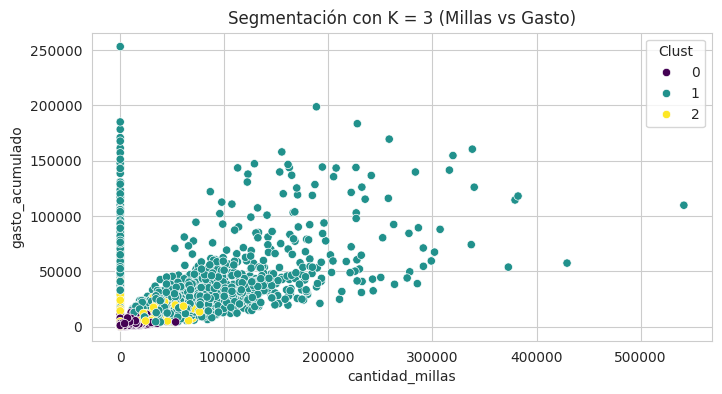


 EVALUANDO MODELO CON K = 4 


,cantidad_millas,gasto_acumulado,ingreso_mensual,cant_vuelos
Clust,,,,
0,4247.793476,6918.852675,3856.008686,13.902528
1,46026.865214,31551.464217,7619.104093,52.567616
2,2081.650259,3018.566953,2485.132556,14.127375
3,1148.557658,1896.954556,861.900059,8.364873


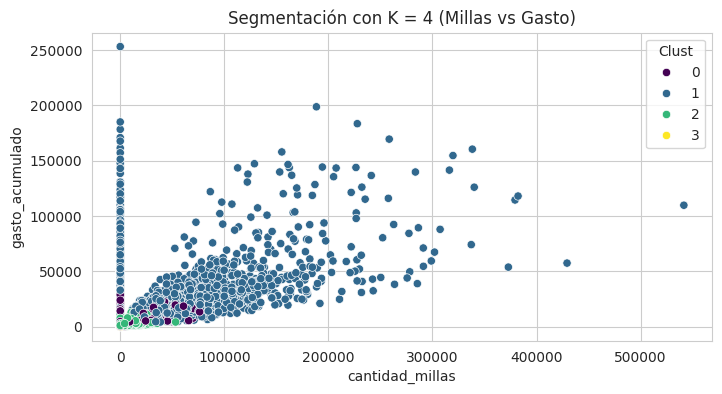


 EVALUANDO MODELO CON K = 5 


,cantidad_millas,gasto_acumulado,ingreso_mensual,cant_vuelos
Clust,,,,
0,521.646877,1017.990396,424.358689,3.970934
1,5455.450000,8796.050860,5845.624561,17.173684
2,2021.230031,2932.272101,2205.225666,13.717650
3,5118.471255,8517.075609,4289.218623,15.107962
4,50689.251405,32675.377374,7534.665304,55.415943


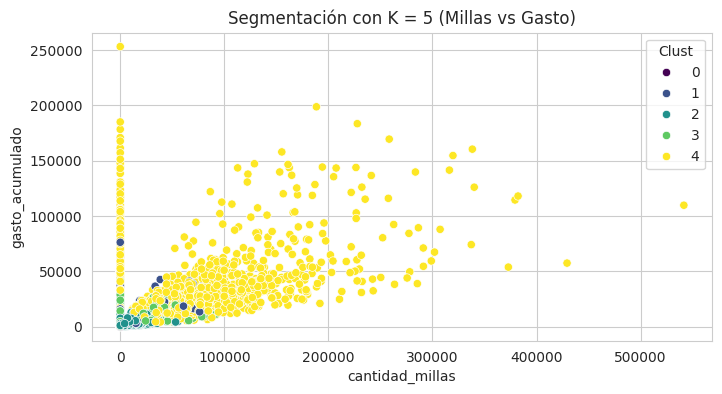

In [ ]:
# --- PASO 5: COMPARACIÓN Y VALIDACIÓN (K=2, 3, 4 y 5) ---
import matplotlib.pyplot as plt
import seaborn as sns

# Definimos aquí las variables que queremos comparar para evitar el NameError
# (Podés poner todas o solo las 3 críticas, acá te pongo las 3 principales para que sea claro)
cols_comparar = ["cantidad_millas", "gasto_acumulado", "ingreso_mensual", "cant_vuelos"]

for k in [2, 3, 4, 5]:
    print(f"\n" + "="*50)
    print(f" EVALUANDO MODELO CON K = {k} ")
    print("="*50)

    # 1. Entrenamos con datos escalados
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    labels = km.fit_predict(data_kmeans_scaled)

    # 2. Mostramos promedios (Usando la lista que definimos arriba)
    resumen = data_kmeans.assign(Clust=labels).groupby("Clust")[cols_comparar].mean()
    display(resumen)

    # 3. Gráfico de comparación
    plt.figure(figsize=(8, 4))
    # Cambiamos x="cant_vuelos" por x="cantidad_millas"
    sns.scatterplot(data=data_kmeans.assign(Clust=labels), x="cantidad_millas", y="gasto_acumulado", hue="Clust", palette="viridis")
    plt.title(f"Segmentación con K = {k} (Millas vs Gasto)")
    plt.show()

In [ ]:
# --- PASO 6: MODELO FINAL Y ASIGNACIÓN DEFINITIVA (K=3) ---
# Elegimos K=3 basándonos en el Codo y la comparación anterior
num_clusters = 3
kmeans_final = KMeans(n_clusters=num_clusters, n_init=10, random_state=0)

# Entrenamos y guardamos la etiqueta en el dataframe original
data_kmeans["Cluster"] = kmeans_final.fit_predict(data_kmeans_scaled)

print("¡Modelo K=3 aplicado y guardado como definitivo!")
# --- VALIDACIÓN DEL MODELO FINAL ---
# Ahora sí, kmeans_final ya existe porque se ejecutó en el Paso 6
score_final = silhouette_score(data_kmeans_scaled, kmeans_final.labels_)

print("\n" + "="*40)
print(f"MÉTRICA DE COHESIÓN Y SEPARACIÓN (K={num_clusters})")
print(f"Coeficiente de Silueta Final: {score_final:.4f}")
print("="*40)

if score_final > 0.5:
    print("Interpretación: Estructura sólida, clústeres bien definidos.")
elif score_final > 0.25:
    print("Interpretación: Estructura razonable, aunque existen algunos solapamientos.")
else:
    print("Interpretación: Estructura débil, los clústeres están muy cerca unos de otros.")

¡Modelo K=3 aplicado y guardado como definitivo!

MÉTRICA DE COHESIÓN Y SEPARACIÓN (K=3)
Coeficiente de Silueta Final: 0.1656
Interpretación: Estructura débil, los clústeres están muy cerca unos de otros.


--- IMPORTANCIA TÉCNICA DE LAS VARIABLES ---


,Poder de Separación %
cantidad_millas,141.731739
gasto_acumulado_extra,110.462295
gasto_acumulado,109.266274
cant_vuelos,85.858798
programaMillas,69.499231
ingreso_mensual,58.773280
anticipacion_compra_promedio,20.287701
edad,3.230990


/tmp/ipykernel_4229/2438418599.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=discriminacion.index, y=discriminacion.values, palette="magma")


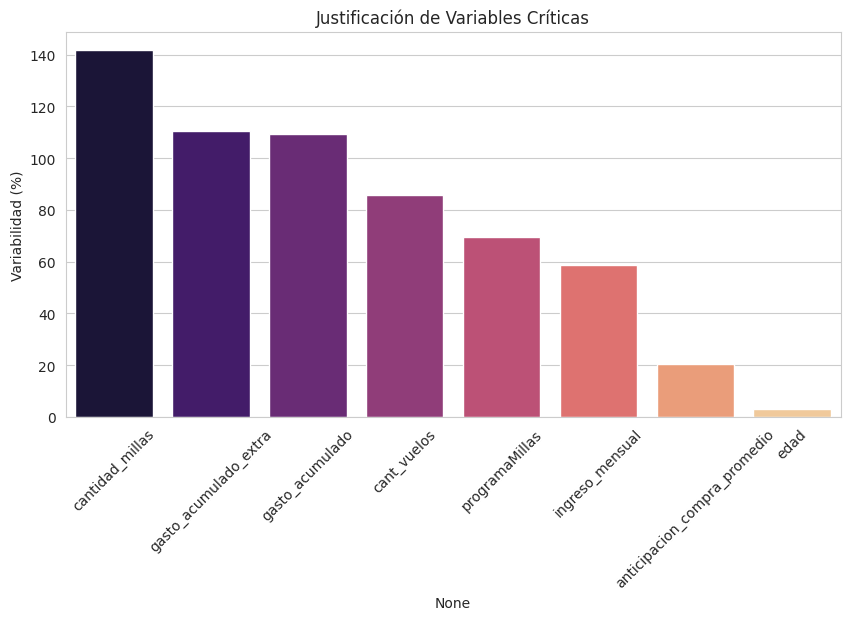

In [ ]:
# ============================================================
# JUSTIFICACIÓN TÉCNICA: PODER DISCRIMINANTE (CELDA 6.5)
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Definimos la lista ACÁ ADENTRO para que no tire NameError
columnas_para_justificar = [
    "edad", "cant_vuelos", "gasto_acumulado",
    "gasto_acumulado_extra", "cantidad_millas",
    "ingreso_mensual", "anticipacion_compra_promedio", "programaMillas", "clase_preferida"
]

# 2. Filtramos las columnas que realmente existen en data_kmeans
cols_finales = [c for c in columnas_para_justificar if c in data_kmeans.columns]

# 3. Calculamos las medias por clúster
medias_justif = data_kmeans.groupby("Cluster")[cols_finales].mean()

# 4. Calculamos la variabilidad (%)
# (Desvío de las medias / Promedio de las medias) * 100
discriminacion = (medias_justif.std() / medias_justif.mean() * 100).sort_values(ascending=False)

# 5. Mostramos la tabla y el gráfico
print("--- IMPORTANCIA TÉCNICA DE LAS VARIABLES ---")
display(discriminacion.to_frame(name="Poder de Separación %"))

plt.figure(figsize=(10, 5))
sns.barplot(x=discriminacion.index, y=discriminacion.values, palette="magma")
plt.xticks(rotation=45)
plt.title("Justificación de Variables Críticas")
plt.ylabel("Variabilidad (%)")
plt.show()

--- CARACTERIZACIÓN FINAL DE LOS SEGMENTOS ---


,edad,cant_vuelos,gasto_acumulado,gasto_acumulado_extra,cantidad_millas,ingreso_mensual,anticipacion_compra_promedio,programaMillas
Cluster,,,,,,,,
0,37.289236,12.948105,2770.262785,398.305813,1887.210038,2129.900183,20.692036,0.203796
1,39.778094,53.789000,32341.142551,4718.293898,48421.027027,7583.875771,14.004267,0.609294
2,38.496270,14.311779,8140.109824,1150.961533,4842.173412,4301.611350,20.119376,0.200995


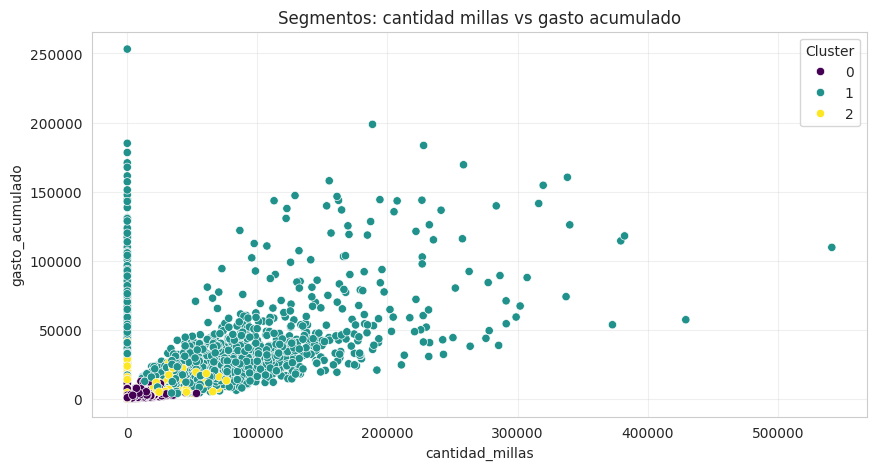

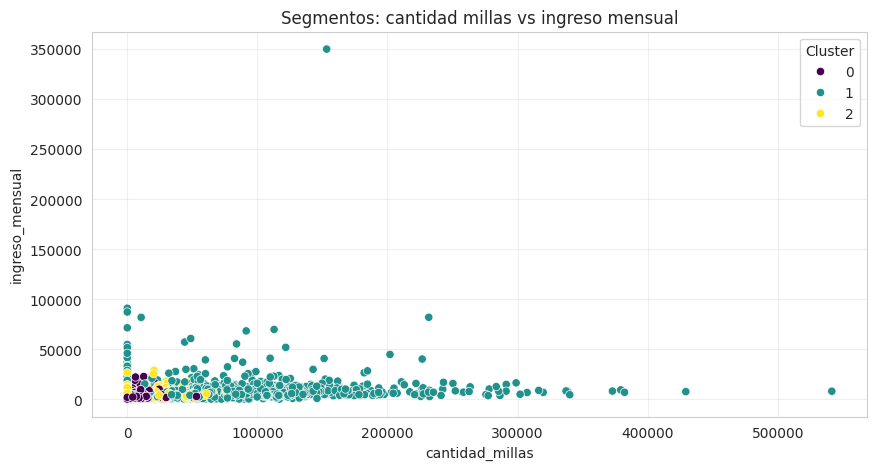

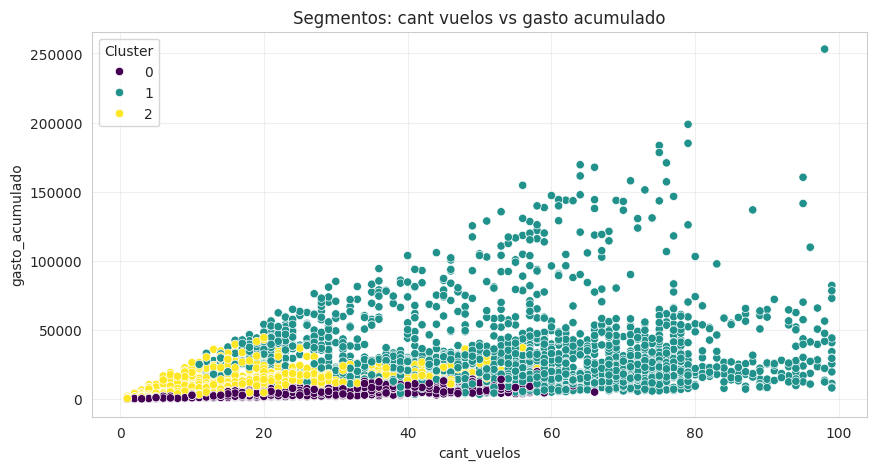

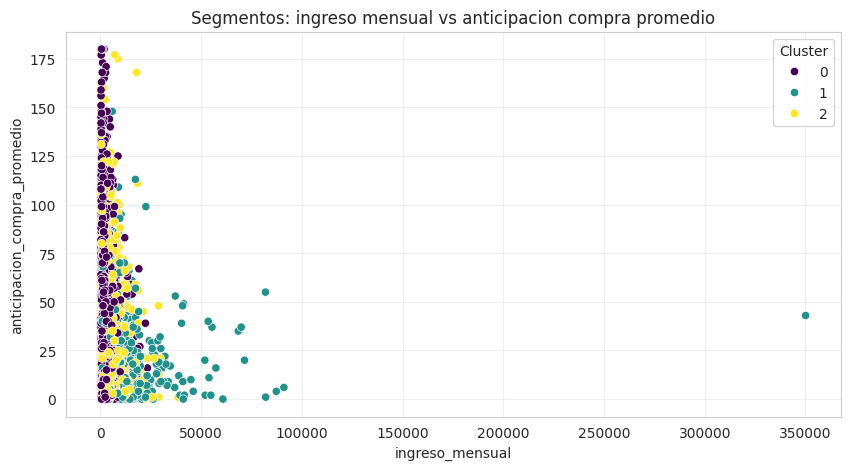

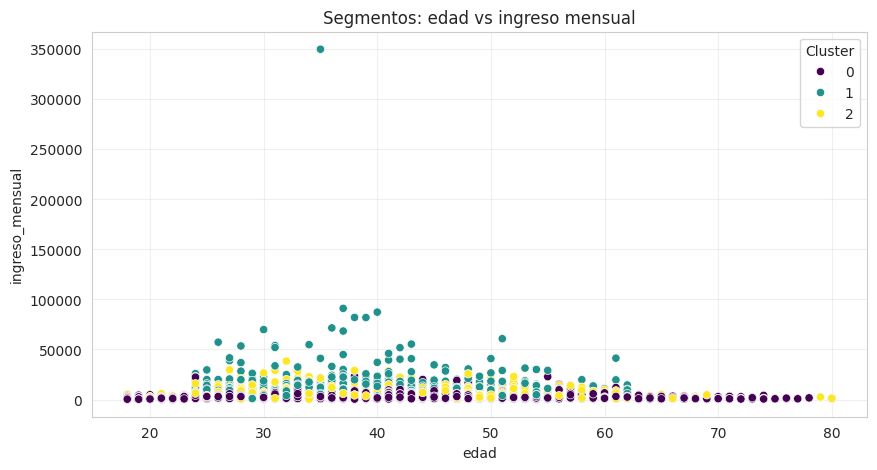

In [ ]:
# --- PASO 7: ANÁLISIS DETALLADO DEL MODELO ELEGIDO ---
# 1. Tabla de Promedios Completa

# CAMBIO AQUÍ: Borré "clase_preferida" de esta lista porque ya no existe como columna única
columnas_interes = ["edad", "cant_vuelos", "gasto_acumulado", "gasto_acumulado_extra", "cantidad_millas", "ingreso_mensual", "anticipacion_compra_promedio", "programaMillas"]

print("--- CARACTERIZACIÓN FINAL DE LOS SEGMENTOS ---")

# Como en el Paso 6 ya hiciste: data_kmeans["Cluster"] = ..., acá solo agrupamos
display(data_kmeans.groupby("Cluster")[columnas_interes].mean())

# 2. Batería de Gráficos de Dispersión
pares = [
    ("cantidad_millas", "gasto_acumulado"),
    ("cantidad_millas", "ingreso_mensual"),
    ("cant_vuelos", "gasto_acumulado"),
    ("ingreso_mensual", "anticipacion_compra_promedio"),
    ("edad", "ingreso_mensual")
]

for x_col, y_col in pares:
    plt.figure(figsize=(10, 5))
    sns.scatterplot(data=data_kmeans, x=x_col, y=y_col, hue="Cluster", palette="viridis")
    plt.title(f"Segmentos: {x_col.replace('_',' ')} vs {y_col.replace('_',' ')}")
    plt.grid(True, alpha=0.3)
    plt.show()